<a href="https://colab.research.google.com/github/JasonLou622/Hospital-readmissions-analysis/blob/main/diabetes_readmission_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd, sqlite3 # pandas works with tables
                             # sqlite 3 lets Python talk to a SQL database.

df = pd.read_csv("diabetic_readmissions_data/diabetic_data.csv") # dataframe AS df
# reads the csv file into Python as a table.

print(df.shape) # df.shape gives (rows, columns)
df.info()       # info() lists each column with its count of non-empty values
                # and its type.
                # 'object' means text, 'int64' means whole numbers.

(101766, 50)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int

Notes:
1. 'max_glu_serum' has only 5,346 values and 'A1Cresult' only 17,018, out of 101,766 rows. Most of those tests are missing.

In [2]:
conn = sqlite3.connect("diabetes.db")
# creates a small database file and opens a connection to it.

df.to_sql("diabetes_data", conn, if_exists="replace", index=False)
# copies the table from diabetic_data.csv into the dataset df as a SQL table
# name as diabetes_data
# conn is like an address (or phone line) used to talk to the database.
# if_exists="replace" means overwrite
# 'index=False' means don't add an extra row-number column

print(pd.read_sql("SELECT * FROM diabetes_data LIMIT 25", conn))
# pd.read_sql a pandas function
# use and run the context in the double quotes as a snippet of SQL code
# conn, connects to the table (diabetes_data) in diabetes.db

    encounter_id  patient_nbr             race  gender       age weight  \
0        2278392      8222157        Caucasian  Female    [0-10)      ?   
1         149190     55629189        Caucasian  Female   [10-20)      ?   
2          64410     86047875  AfricanAmerican  Female   [20-30)      ?   
3         500364     82442376        Caucasian    Male   [30-40)      ?   
4          16680     42519267        Caucasian    Male   [40-50)      ?   
5          35754     82637451        Caucasian    Male   [50-60)      ?   
6          55842     84259809        Caucasian    Male   [60-70)      ?   
7          63768    114882984        Caucasian    Male   [70-80)      ?   
8          12522     48330783        Caucasian  Female   [80-90)      ?   
9          15738     63555939        Caucasian  Female  [90-100)      ?   
10         28236     89869032  AfricanAmerican  Female   [40-50)      ?   
11         36900     77391171  AfricanAmerican    Male   [60-70)      ?   
12         40926     8550

Notes:
1. The column 'weight' shows '?' in the column 'weight'. The dataset uses '?' for missing values.

In [3]:
# Clean the data and note its limits
df = df.replace("?", pd.NA)
print(df.isna().sum().sort_values(ascending=False).head(10))
# Shows which columns have the most missing values.

weight               98569
max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
encounter_id             0
dtype: int64


Notes:

Indicating columns weight 96.9% (98569 out of 101766), max_glu_serum 94.7%, A1Cresult 83.3%, and medical_specialty 49.1% of values are missing. These percentages are from all 101,766 rows.

In [4]:
# Check the IDS_mapping.csv file
df1 = pd.read_csv("diabetic_readmissions_data/IDS_mapping.csv")
df1.shape
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67 entries, 0 to 66
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   admission_type_id  65 non-null     object
 1   description        62 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


Notes:

The IDS_mapping note should have three tables stacked together (admission type, discharge disposition, admission source).

In [5]:
# Considering to list all the unique values it contains.
df1['description'].unique()

array(['Emergency', 'Urgent', 'Elective', 'Newborn', 'Not Available', nan,
       'Trauma Center', 'Not Mapped', 'description', 'Discharged to home',
       'Discharged/transferred to another short term hospital',
       'Discharged/transferred to SNF', 'Discharged/transferred to ICF',
       'Discharged/transferred to another type of inpatient care institution',
       'Discharged/transferred to home with home health service',
       'Left AMA',
       'Discharged/transferred to home under care of Home IV provider',
       'Admitted as an inpatient to this hospital',
       'Neonate discharged to another hospital for neonatal aftercare',
       'Expired',
       'Still patient or expected to return for outpatient services',
       'Hospice / home', 'Hospice / medical facility',
       'Discharged/transferred within this institution to Medicare approved swing bed',
       'Discharged/transferred/referred another institution for outpatient services',
       'Discharged/transferred/refer

Notes:

Patients who passed away (expired) or went to hospice are not expected to be readmitted.

In [6]:
df1.head(25)

,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NaN
6,7,Trauma Center
7,8,Not Mapped
8,NaN,NaN
9,discharge_disposition_id,description


Notes:

1. Rows 0-7: Map codes as the admission type;
2. Row 8: Completely blank (NaN);
3. Row 9: A brand new header row for discharge_disposition_id.
4. Row 10-23: Map codes the rows for discharge_disposition_id with descriptions like "Expired" and "Hospice".

In [7]:

# Find descriptions containing expired or hospice
filtered_df1 = df1[ # creates a new filtered subset dataframe by taking out rows out of df1 -- the IDS_mapping lookup table.
    df1["description"].str.contains(  # .str treats every row/entry in this column as string text
                                      # .contains(...) a pandas string method that checks if a specific word or pattern exists
                                      # inside each text row/entry.
        "expired|hospice",            # spaces matter, pandas will literally search for the phrase "expired " or "  Hospice".
        case=False,                   # search case-insensitive
        na=False                      # Tells pandas how to handle missing values like (NaN or empty cells) in this column.
                                      # treats any missing cell as a "False" (don't match this row), so the code doesn't crash.
    )
]
filtered_df1


,admission_type_id,description
20,11,Expired
22,13,Hospice / home
23,14,Hospice / medical facility
28,19,"Expired at home. Medicaid only, hospice."
29,20,"Expired in a medical facility. Medicaid only, ..."
30,21,"Expired, place unknown. Medicaid only, hospice."
66,26,Transfer from Hospice


Notes:

Filtering encounters of ending in death or hospice.

In [ ]:

# counts the encounters to exclude.

query = '''
SELECT COUNT(*) AS encounters_to_remove
FROM diabetes_data
WHERE discharge_disposition_id IN (11, 13, 14, 19, 20, 21);
'''

print(pd.read_sql(query, conn))

   encounters_to_remove
0                  2423


Notes:

1. Excludes these patients from readmission cohorts, since they are not expected to be readmitted, lowering readmission rates and misleading the final analysis result.
2. Transfer from Hospice is still an admission source, not a discharge code, so I didn't select it into the exclusion list.

In [9]:
# Exclude patients who expired or were discharged to hospice from the analysis.
conn.execute("DROP TABLE IF EXISTS diabetes_data_cleaned")
conn.execute('''
CREATE TABLE diabetes_data_cleaned AS
SELECT *
FROM diabetes_data
WHERE discharge_disposition_id NOT IN (11, 13, 14, 19, 20 ,21);
''')
conn.commit()

print(pd.read_sql("SELECT COUNT(*) AS encounters FROM diabetes_data_cleaned", conn))

   encounters
0       99343


Notes:

The number of encounters reduces from 101,766 to 99,343 (2,423 in difference).

In [10]:
# Analysis 1: Measures the total number of encounters were readmitted in 30 days
query = """
SELECT 
    readmitted, 
    COUNT(*) AS encounters,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM diabetes_data_cleaned), 1) AS percentage
FROM diabetes_data_cleaned
GROUP BY readmitted;
"""
print(pd.read_sql(query, conn))


# In the triple quotes, allowing to write a multi-line piece of text.
# Python holds it as a text.
# 'pd.read_sql' sends that text through the connection, runs it,
# and brings the answer back as a table.

  readmitted  encounters  percentage
0        <30       11314        11.4
1        >30       35502        35.7
2         NO       52527        52.9


Notes:
1. Readmissions: 11,314 encounters ('<30', about 11.4%) were followed by a readmission within 30 days, 35,502 after 30 days('>30', about 35.7%), and 52,527 not at all ('NO', about 52.9%). The three add up to 99,343, so nothing was lost.

In [11]:
query = '''
SELECT
    COUNT(*) AS encounters,
    COUNT(DISTINCT patient_nbr) AS unique_patients
FROM diabetes_data_cleaned;
'''
print(pd.read_sql(query, conn))

   encounters  unique_patients
0       99343            69990


Notes:

Each row is one hospital encounter, and the 99,343 encounters come from 69,990 unique patients, so some patients appear more than once. Rates in this analysis are per encounter.

In [12]:
# Analysis 2: Measures the number of encounters in each age group were readmitted within 30 days.
query = '''
SELECT 
    age,
    COUNT(*) AS encounters_readmitted_in_30d
FROM diabetes_data_cleaned
WHERE readmitted = '<30'
GROUP BY age;
'''
print(pd.read_sql(query, conn))

        age  encounters_readmitted_in_30d
0    [0-10)                             3
1   [10-20)                            40
2   [20-30)                           236
3   [30-40)                           424
4   [40-50)                          1024
5   [50-60)                          1667
6   [60-70)                          2493
7   [70-80)                          3054
8   [80-90)                          2065
9  [90-100)                           308


Notes:
1. Age group [70-80) has the most encounters followed by a readmission within 30 days (3,054), but it is also the largest group (25,331 encounters), so a readmission rate is a fairer comparison than the count.

        age  encounters  readmitted_in_30d  pct_readmitted_in_30d
0    [0-10)         160                  3                    1.9
1   [10-20)         690                 40                    5.8
2   [20-30)        1649                236                   14.3
3   [30-40)        3764                424                   11.3
4   [40-50)        9607               1024                   10.7
5   [50-60)       17060               1667                    9.8
6   [60-70)       22059               2493                   11.3
7   [70-80)       25331               3054                   12.1
8   [80-90)       16434               2065                   12.6
9  [90-100)        2589                308                   11.9


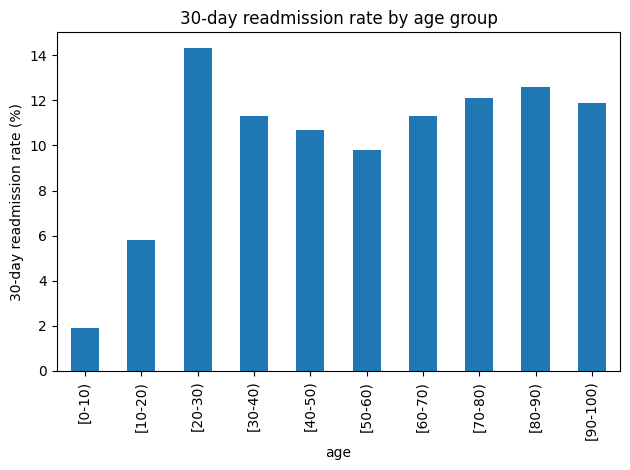

In [13]:
# Analysis 3: Examines the 30-day readmission rate in each age group.
query = '''
SELECT
    age,
    COUNT(*) AS encounters,
    SUM(1) FILTER (WHERE readmitted = '<30') AS readmitted_in_30d,
    ROUND(100.0 * (SUM(1) FILTER (WHERE readmitted = '<30')) / COUNT(*), 1) AS pct_readmitted_in_30d
FROM diabetes_data_cleaned
GROUP BY age
ORDER BY age;
'''
result = pd.read_sql(query, conn)
print(result)

import matplotlib.pyplot as plt
result.plot(x="age", y="pct_readmitted_in_30d", kind="bar", legend=False)
plt.ylabel("30-day readmission rate (%)")
plt.title("30-day readmission rate by age group")
plt.tight_layout()
plt.show()

Notes:

Age group [0-10) has the lowest percentage 1.9% (3 out of 160 encounters) were readmitted within 30 days; age group [70-80) has a rate at 12.1% with the most encounters (3,054 out of 25,331); age group [20-30) has the highest rate 14.3% (236 out of 1,649 encounters).

    time_in_hospital  encounters  pct_readmitted_30d
0                  1       13824                 8.4
1                  2       16891                10.1
2                  3       17432                10.8
3                  4       13684                12.0
4                  5        9749                12.3
5                  6        7355                12.9
6                  7        5696                13.1
7                  8        4271                14.6
8                  9        2879                14.3
9                 10        2262                14.8
10                11        1770                10.8
11                12        1383                14.0
12                13        1152                12.9
13                14         995                13.5


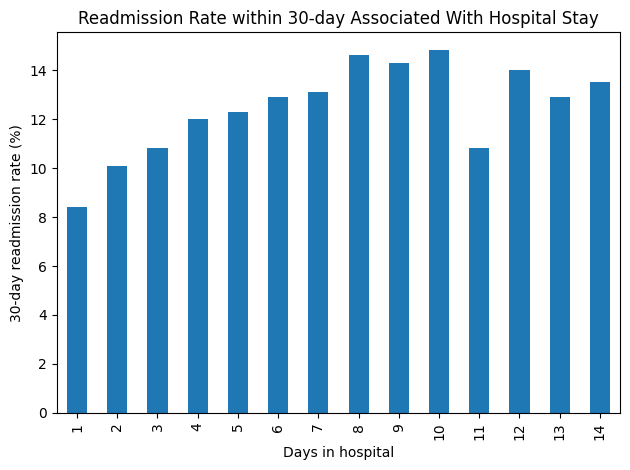

In [14]:
# Analysis 4: Examines whether a longer hospital stay is associated with patient readmission.
query = '''
SELECT
    time_in_hospital,
    COUNT(*) AS encounters,
    ROUND(100.0 * SUM(1) FILTER (WHERE readmitted = '<30') / COUNT(*), 1) AS pct_readmitted_30d
FROM diabetes_data_cleaned
GROUP BY time_in_hospital
ORDER BY time_in_hospital
'''

result = pd.read_sql(query, conn)
print(result)

result.plot(x="time_in_hospital", y="pct_readmitted_30d", kind="bar", legend=False)
plt.xlabel("Days in hospital")
plt.ylabel("30-day readmission rate (%)")
plt.title("Readmission Rate within 30-day Associated With Hospital Stay")
plt.tight_layout()
plt.show()

Notes:

The rates rises from 8.4% at one day to 14.8% at ten days, then fluctuates from 11 to 14 days (10.8%, 14.0%, 12.9%, 13.5%).

In [15]:
# Analysis 5: Examines the average time in hospital for each age group
query = '''
SELECT
    age,
    COUNT(*) AS encounters,
    ROUND(AVG(time_in_hospital), 2) AS Average_time_in_hospital,
    ROUND(100.0 * SUM(1) FILTER (WHERE readmitted = '<30') / COUNT(*), 1) AS pct_readmitted_30d
FROM diabetes_data_cleaned
GROUP BY age
ORDER BY age;
'''

print(pd.read_sql(query, conn))


        age  encounters  Average_time_in_hospital  pct_readmitted_30d
0    [0-10)         160                      2.52                 1.9
1   [10-20)         690                      3.19                 5.8
2   [20-30)        1649                      3.57                14.3
3   [30-40)        3764                      3.80                11.3
4   [40-50)        9607                      4.03                10.7
5   [50-60)       17060                      4.12                 9.8
6   [60-70)       22059                      4.37                11.3
7   [70-80)       25331                      4.57                12.1
8   [80-90)       16434                      4.79                12.6
9  [90-100)        2589                      4.78                11.9


Notes:
1. Noticed that average hospital stay rises with age, from about 2.52 (age under 10) to 4.79 (age [80-90)) days.
2. Average stay rises with age, but the readmission rate does not rise steadily with age.

In [16]:
# Analysis 6: Examines if the number of earlier inpatient admissions (number_inpatient) relates to readmission.
query = '''
SELECT 
    number_inpatient,
    COUNT(*) AS encounters,
    ROUND(100.0 * SUM(1) FILTER (WHERE readmitted = '<30') / COUNT(*), 1) AS pct_readmitted_30d
FROM diabetes_data_cleaned
GROUP BY number_inpatient
HAVING COUNT(*) >= 100
ORDER BY number_inpatient;
'''

print(pd.read_sql(query, conn))

   number_inpatient  encounters  pct_readmitted_30d
0                 0       66245                 8.6
1                 1       18984                13.3
2                 2        7300                17.9
3                 3        3271                21.0
4                 4        1574                24.1
5                 5         791                32.0
6                 6         474                34.8
7                 7         262                36.3
8                 8         145                46.2
9                 9         109                43.1


Notes:

1. The 30-day readmission rate rises steadily, from 8.6% for encounters without earlier hospital admissions (66,245 encounters) to 46.2% for encounters with eight earlier hospital admissions (145 encounters), is about five times higher.
2. The 30-day readmission rate could rise significantly after one (13.3%) or two (17.9%) earlier hospital admissions comparing with encounters who had no earlier hospital stay (8.6%).

In [20]:
# Analysis 7: Determines whether medical_specialty associates with the 30-day readmission rate.
query = '''
SELECT 
    medical_specialty,
    COUNT(*) AS encounters,
    COUNT(*) FILTER (WHERE readmitted = '<30') AS readmitted_30d,
    ROUND(100.0 * SUM(1) FILTER (WHERE readmitted = '<30') / COUNT(*), 1) AS pct_readmitted_30d
FROM diabetes_data_cleaned
WHERE medical_specialty != '?'
GROUP BY medical_specialty
HAVING COUNT(*) >= 500
ORDER BY pct_readmitted_30d DESC;
'''

print(pd.read_sql(query, conn))

                  medical_specialty  encounters  readmitted_30d  \
0                        Nephrology        1539             248   
1                  Surgery-Vascular         525              74   
2                        Psychiatry         853             104   
3            Family/GeneralPractice        7252             879   
4                  InternalMedicine       14237            1642   
5                  Emergency/Trauma        7419             845   
6                  Gastroenterology         538              61   
7                   Surgery-General        3059             342   
8                       Pulmonology         854              96   
9                       Orthopedics        1392             151   
10                          Urology         682              67   
11                      Radiologist        1121             102   
12                       Cardiology        5279             424   
13       Orthopedics-Reconstructive        1230              9

Notes:

1. Nephrology is highest at 16.1%, against an overall rate of 11.4%, while Obstetrics and Gynecology (4.8%) and Surgery-Cardiovascular/Thoracic (6.7%) are lowest.
2. Internal Medicine has the most encounters (14,237), sixteen specialties have at least 500 encounters, and about half the rows have no specialty recorded.

      A1Cresult  encounters  readmitted_30d  pct_readmitted_30d
0  Not measured       82509            9641                11.7
1            >7        3775             383                10.1
2            >8        8137             809                 9.9
3          Norm        4922             481                 9.8


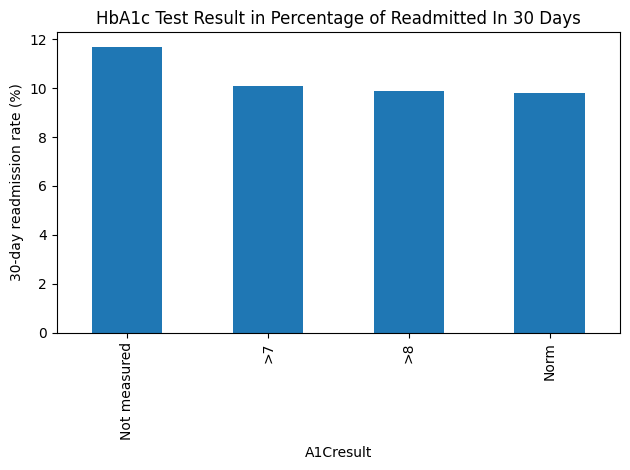

In [19]:
# Analysis 8: Determines whether the HbA1c test relates to readmission.
query = '''
SELECT 
    COALESCE(A1Cresult, 'Not measured') AS A1Cresult,
    COUNT(*) AS encounters,
    COUNT(*) FILTER (WHERE readmitted = '<30') AS readmitted_30d,
    ROUND(100.0 * SUM(1) FILTER (WHERE readmitted = '<30') / COUNT(*), 1) AS pct_readmitted_30d
FROM diabetes_data_cleaned
GROUP BY A1Cresult
'''
print(pd.read_sql(query, conn))

result = pd.read_sql(query, conn)
# print(result.columns)
result.plot(x="A1Cresult", y="pct_readmitted_30d", kind="bar", legend=False)
plt.ylabel("30-day readmission rate (%)")
plt.title("HbA1c Test Result in Percentage of Readmitted In 30 Days")
plt.tight_layout()
plt.show()

Notes:
1. Suggests that having an HbA1c test is associated with a lower likelihood of 30-day readmission rate, as only 9.9% of encounters who received an HbA1c test were readmitted within 30 days. In contrast, encounters who had no HbA1c result recorded had a higher rate (11.7%) of readmission within 30 days, but the difference is small (about 2 points).

Summary:

This analysis evaluates 101,766 hospital encounters of patients with diabetes to find which factors are associated with 30-day readmissions. It is a descriptive analysis, and rates are per encounter. After excluding 2,423 encounters that ended in death or hospice (not expected to be readmitted), 99,343 encounters remained (from 69,990 unique patients), with a 30-day readmission rate of 11.4%. For ages 30 and older, rates ranged from 9.8% to 12.6%; ages 20 to 30 were highest (14.3%), and the youngest groups were lowest but small (1.9% for 160 encounters under age 10). The strongest association was with the number of earlier inpatient admissions: the rate rose from 8.6% with none (66,245 encounters) to 13.3% with one, 17.9% with two, and 36.3% with seven (262 encounters); groups with eight or more are small (under 145 encounters). The rate also rose with length of stay, from 8.4% at one day to about 14.8% at ten days. Furthermore, the average hospital stay rose with age, from about 2.52 (age under 10) to 4.79 days (age [80-90)). Among the 16 specialties with at least 500 encounters, rates ranged from 4.8% (Obstetrics and Gynecology) to 16.1% (Nephrology), but about half of encounters have no specialty recorded. Encounters with an HbA1c result had a slightly lower rate (9.9%) than those without (11.7%), a small difference. These results show associations, not causes. 